# 02 - Supervised models

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, overlap_with_train, train_val_split, FEATURES
from netad.preprocessing import build_preprocessor
from netad.evaluation import (
    evaluate_binary, choose_threshold, evaluate_multiclass, evaluate_test,
    save_result, plot_roc_pr, plot_confusion,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
y_test = test_df["label"]
y_test_multi = test_df["attack_cat"]
unseen = ~overlap_with_train(train_df, test_df)

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
Xm_tr, Xm_val, ym_tr, ym_val = train_val_split(train_df, "attack_cat")

len(X_tr), len(X_val), len(Xm_tr), len(Xm_val), len(X_test), int(unseen.sum())

(80752, 20189, 80341, 20086, 82332, 73791)

Binary: the threshold is picked on validation with an FPR budget of 1% and then used as is on test.
Every test result is reported on the full test set and on the unseen rows.

In [4]:
MAX_FPR = 0.01
RUN_SEARCH = False  # True reruns the hyperparameter search (~1.5 h), False refits with the params in results.json

## Dummy baseline

Predicts the class priors seen in train, the same score for every flow. Used to check the whole flow end to end,
and as the floor any real model has to beat.

In [5]:
dummy = make_pipeline(build_preprocessor(), DummyClassifier(strategy="prior"))
dummy.fit(X_tr, y_tr)

scores_val = dummy.predict_proba(X_val)[:, 1]
scores_test = dummy.predict_proba(X_test)[:, 1]
threshold = choose_threshold(y_val, scores_val, "fpr", max_fpr=MAX_FPR)

metrics = {
    "val": evaluate_binary(y_val, scores_val, threshold, categories=train_df.loc[X_val.index, "attack_cat"]),
    **evaluate_test(evaluate_binary, y_test, scores_test, unseen, categories=y_test_multi, threshold=threshold),
}
save_result("Dummy (prior)", "binary", metrics, {"threshold_mode": "fpr", "max_fpr": MAX_FPR})

{k: {m: v[m] for m in ["recall", "fpr", "roc_auc", "pr_auc"]} for k, v in metrics.items()}

{'val': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.4877408489771658},
 'test': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.5506000097167566},
 'test_unseen': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.5185320703066769}}

Same scores with the max-F1 threshold: flags every flow.

In [6]:
t_f1 = choose_threshold(y_val, scores_val, "f1")
m = evaluate_binary(y_test, scores_test, t_f1)
m["recall"], m["fpr"], m["precision"]

(1.0, 1.0, 0.5506000097167566)

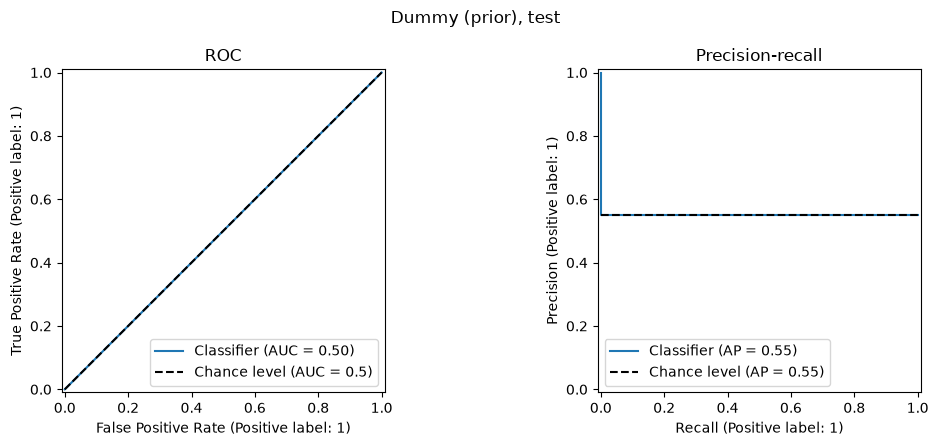

In [7]:
fig = plot_roc_pr(y_test, scores_test, "Dummy (prior), test")
plt.show()

In [8]:
dummy_multi = make_pipeline(build_preprocessor(), DummyClassifier(strategy="most_frequent"))
dummy_multi.fit(Xm_tr, ym_tr)

labels = sorted(ym_tr.unique())
metrics = {
    "val": evaluate_multiclass(ym_val, dummy_multi.predict(Xm_val), labels),
    **evaluate_test(evaluate_multiclass, y_test_multi, dummy_multi.predict(X_test), unseen, labels=labels),
}
save_result("Dummy (most frequent)", "multiclass", metrics)

{k: {m: v[m] for m in ["accuracy", "macro_f1"]} for k, v in metrics.items()}

{'val': {'accuracy': 0.5148859902419596, 'macro_f1': 0.0679768634152754},
 'test': {'accuracy': 0.44939999028324346, 'macro_f1': 0.06201186605436933},
 'test_unseen': {'accuracy': 0.481467929693323,
  'macro_f1': 0.0649987650820077}}

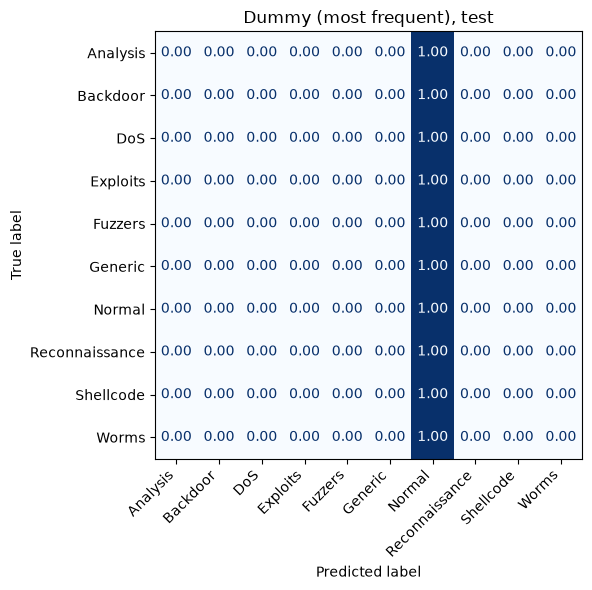

In [9]:
fig = plot_confusion(metrics["test"]["confusion_matrix"], labels, "Dummy (most frequent), test")
plt.show()

## Supervised models

Three models, each in `make_pipeline(build_preprocessor(), model)`: logistic regression (linear baseline), random forest and histogram gradient boosting.

- Hyperparameters: `RandomizedSearchCV` (30 candidates per model) with 3-fold stratified CV on the training part only (one row per feature vector, so folds don't share flows).
- Binary search metric: ROC-AUC restricted to FPR <= 1% (standardized, 0.5 = random, 1 = perfect), since that is the region where the alert threshold will sit. Multi-class: macro-F1.
- `RUN_SEARCH = False` (Setup) skips the search: each model is refit with the hyperparameters and CV score saved in `reports/results.json` by the last search, a few minutes instead of an hour and a half.
- Validation is used to pick the threshold and to compare models. The test set is only used once, in the "Test" section.

In [10]:
import json

import pandas as pd
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from netad.evaluation import FIGURES_DIR, RESULTS_PATH
from netad.preprocessing import TTL_COLUMNS

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
pauc = make_scorer(roc_auc_score, response_method="predict_proba", max_fpr=MAX_FPR)


def tune(model, space, X, y, scoring, n_iter=30):
    search = RandomizedSearchCV(
        make_pipeline(build_preprocessor(), model), space,
        n_iter=n_iter, scoring=scoring, cv=cv, n_jobs=-1, random_state=42,
    )
    return search.fit(X, y)


def clean(params):
    """best_params_ without the pipeline prefix and numpy types, for results.json"""
    return {k.split("__")[-1]: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}


def fit_best(name, task, model, space, X, y, scoring):
    """Tuned pipeline, its params and CV score.

    With RUN_SEARCH off the params and CV score come from the results.json entry of the last search.
    """
    if RUN_SEARCH:
        search = tune(model, space, X, y, scoring)
        return {"model": search.best_estimator_, "params": clean(search.best_params_), "cv": search.best_score_}

    results = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))
    entry = next(r for r in results if (r["model"], r["task"]) == (name, task))
    # binary entries also hold threshold settings, keep only the model's own params
    params = {k: v for k, v in entry["params"].items() if k in model.get_params()}
    pipe = make_pipeline(build_preprocessor(), clone(model).set_params(**params)).fit(X, y)
    return {"model": pipe, "params": params, "cv": entry.get("cv_score")}

### Binary: tuning

In [11]:
binary_space = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000),
        {"logisticregression__C": loguniform(1e-3, 1e4)},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42),
        {
            "randomforestclassifier__n_estimators": [200, 400, 800],
            "randomforestclassifier__max_depth": [None, 15, 20, 30, 40],
            "randomforestclassifier__min_samples_leaf": [1, 2, 5],
            "randomforestclassifier__max_features": ["log2", "sqrt", 0.3, 0.5, 0.7],
        },
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=42),
        {
            "histgradientboostingclassifier__learning_rate": loguniform(0.01, 0.3),
            "histgradientboostingclassifier__max_iter": [200, 400, 800],
            "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63, 127, 255],
            "histgradientboostingclassifier__min_samples_leaf": [10, 20, 50, 100, 200, 400],
            "histgradientboostingclassifier__l2_regularization": loguniform(1e-4, 10),
        },
    ),
}

binary_fit = {}
for name, (model, space) in binary_space.items():
    binary_fit[name] = fit_best(name, "binary", model, space, X_tr, y_tr, pauc)
    print(name, binary_fit[name]["params"])

LogisticRegression {'C': 671.5811311069949}


RandomForest {'n_estimators': 800, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}


HistGradientBoosting {'l2_regularization': 2.276685024868622, 'learning_rate': 0.1538583627271404, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


### Binary: validation

In [12]:
val_categories = train_df.loc[X_val.index, "attack_cat"]

binary = {}
for name, fit in binary_fit.items():
    model = fit["model"]
    s_val = model.predict_proba(X_val)[:, 1]
    threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)
    binary[name] = {
        "model": model,
        "params": fit["params"],
        "cv": fit["cv"],
        "threshold": threshold,
        "val_pauc": roc_auc_score(y_val, s_val, max_fpr=MAX_FPR),
        "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    }

pd.DataFrame({
    name: {
        "cv pAUC": b["cv"],
        "val pAUC": b["val_pauc"],
        "val ROC-AUC": b["val"]["roc_auc"],
        "val recall": b["val"]["recall"],
        "val FPR": b["val"]["fpr"],
        "val precision": b["val"]["precision"],
    }
    for name, b in binary.items()
}).T.round(4)

,cv pAUC,val pAUC,val ROC-AUC,val recall,val FPR,val precision
LogisticRegression,0.7085,0.7020,0.9721,0.5575,0.01,0.9816
RandomForest,0.8198,0.8250,0.9853,0.7453,0.01,0.9862
HistGradientBoosting,0.8232,0.8205,0.9853,0.7515,0.01,0.9863


In [13]:
best_binary = max(binary, key=lambda name: binary[name]["val_pauc"])
best_binary

'RandomForest'

### Multi-class: tuning

`class_weight` is part of the search, so `"balanced"` is kept only if it helps macro-F1 in CV.

In [14]:
multi_space = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000),
        {
            "logisticregression__C": loguniform(1e-3, 1e4),
            "logisticregression__class_weight": [None, "balanced"],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42),
        {
            "randomforestclassifier__n_estimators": [200, 400, 800],
            "randomforestclassifier__max_depth": [None, 15, 20, 30, 40],
            "randomforestclassifier__min_samples_leaf": [1, 2, 5],
            "randomforestclassifier__max_features": ["log2", "sqrt", 0.3, 0.5, 0.7],
            "randomforestclassifier__class_weight": [None, "balanced", "balanced_subsample"],
        },
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=42),
        {
            "histgradientboostingclassifier__learning_rate": loguniform(0.01, 0.3),
            "histgradientboostingclassifier__max_iter": [200, 400, 800],
            "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63, 127, 255],
            "histgradientboostingclassifier__min_samples_leaf": [10, 20, 50, 100, 200, 400],
            "histgradientboostingclassifier__l2_regularization": loguniform(1e-4, 10),
            "histgradientboostingclassifier__class_weight": [None, "balanced"],
        },
    ),
}

multi_fit = {}
for name, (model, space) in multi_space.items():
    multi_fit[name] = fit_best(name, "multiclass", model, space, Xm_tr, ym_tr, "f1_macro")
    print(name, multi_fit[name]["params"])

LogisticRegression {'C': 19.12370886255325, 'class_weight': None}


RandomForest {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 30, 'class_weight': 'balanced'}


HistGradientBoosting {'class_weight': 'balanced', 'l2_regularization': 0.09761125443110447, 'learning_rate': 0.22999586428143728, 'max_iter': 400, 'max_leaf_nodes': 127, 'min_samples_leaf': 10}


### Multi-class: validation

In [15]:
multi = {}
for name, fit in multi_fit.items():
    model = fit["model"]
    multi[name] = {
        "model": model,
        "params": fit["params"],
        "cv": fit["cv"],
        "val": evaluate_multiclass(ym_val, model.predict(Xm_val), labels),
    }

pd.DataFrame({
    name: {
        "cv macro-F1": m["cv"],
        "val macro-F1": m["val"]["macro_f1"],
        "val accuracy": m["val"]["accuracy"],
        "class_weight": m["params"].get("class_weight"),
    }
    for name, m in multi.items()
}).T

,cv macro-F1,val macro-F1,val accuracy,class_weight
LogisticRegression,0.516358,0.518541,0.80932,NaN
RandomForest,0.726072,0.741656,0.858359,balanced
HistGradientBoosting,0.714582,0.737912,0.854874,balanced


In [16]:
best_multi = max(multi, key=lambda name: multi[name]["val"]["macro_f1"])
best_multi

'RandomForest'

## Test

Every model is evaluated once on the full test set and on the unseen rows, then saved to `results.json`.

In [17]:
for name, b in binary.items():
    s_test = b["model"].predict_proba(X_test)[:, 1]
    b["scores_test"] = s_test
    b.update(evaluate_test(evaluate_binary, y_test, s_test, unseen, categories=y_test_multi, threshold=b["threshold"]))
    save_result(name, "binary", {"cv_score": b["cv"], "val": b["val"], "test": b["test"], "test_unseen": b["test_unseen"]},
                {"threshold_mode": "fpr", "max_fpr": MAX_FPR, **b["params"]})

pd.DataFrame({
    (name, subset): {m: b[subset][m] for m in ["recall", "fpr", "precision", "f1", "roc_auc", "pr_auc"]}
    for name, b in binary.items()
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

recall     fpr  precision      f1  roc_auc  \
LogisticRegression   val          0.5575  0.0100     0.9816  0.7111   0.9721   
                     test         0.8042  0.0252     0.9751  0.8815   0.9676   
                     test_unseen  0.7719  0.0234     0.9727  0.8608   0.9632   
RandomForest         val          0.7453  0.0100     0.9862  0.8490   0.9853   
                     test         0.8905  0.0397     0.9649  0.9262   0.9816   
                     test_unseen  0.8710  0.0374     0.9616  0.9141   0.9791   
HistGradientBoosting val          0.7515  0.0100     0.9863  0.8530   0.9853   
                     test         0.9195  0.0481     0.9591  0.9389   0.9849   
                     test_unseen  0.9063  0.0474     0.9537  0.9294   0.9828   

                                  pr_auc  
LogisticRegression   val          0.9665  
                     test         0.9738  
                     test_unseen  0.9666  
RandomForest         val          0.9840  
                     test         0.9861  
                     test_unseen  0.9821  
HistGradientBoosting val          0.9838  
                     test         0.9888  
                     test_unseen  0.9856

Detection rate per attack category (share flagged as attack; for Normal this is the FPR):

In [18]:
by_category = pd.DataFrame({
    (name, subset): {cat: v["flagged"] for cat, v in b[subset]["by_category"].items()}
    for name, b in binary.items()
    for subset in ["test", "test_unseen"]
})
by_category.round(3)

LogisticRegression             RandomForest              \
                             test test_unseen         test test_unseen   
Analysis                    0.910       0.891        0.914       0.895   
Backdoor                    0.931       0.931        0.988       0.988   
DoS                         0.876       0.769        0.957       0.915   
Exploits                    0.803       0.765        0.942       0.931   
Fuzzers                     0.275       0.247        0.382       0.358   
Generic                     0.987       0.986        0.992       0.992   
Normal                      0.025       0.023        0.040       0.037   
Reconnaissance              0.642       0.503        0.962       0.944   
Shellcode                   0.540       0.526        0.870       0.866   
Worms                       0.773       0.773        0.932       0.932   

               HistGradientBoosting              
                               test test_unseen  
Analysis                      0.938       0.924  
Backdoor                      0.983       0.983  
DoS                           0.968       0.946  
Exploits                      0.961       0.956  
Fuzzers                       0.522       0.505  
Generic                       0.998       0.998  
Normal                        0.048       0.047  
Reconnaissance                0.979       0.971  
Shellcode                     0.910       0.907  
Worms                         1.000       1.000

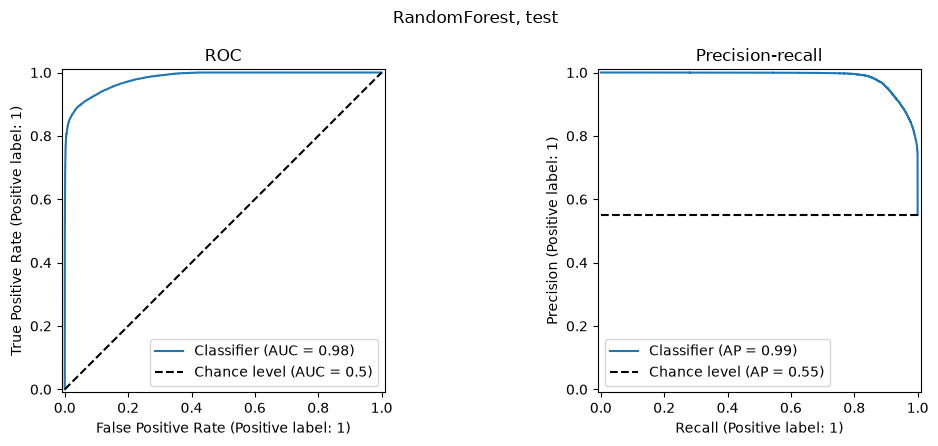

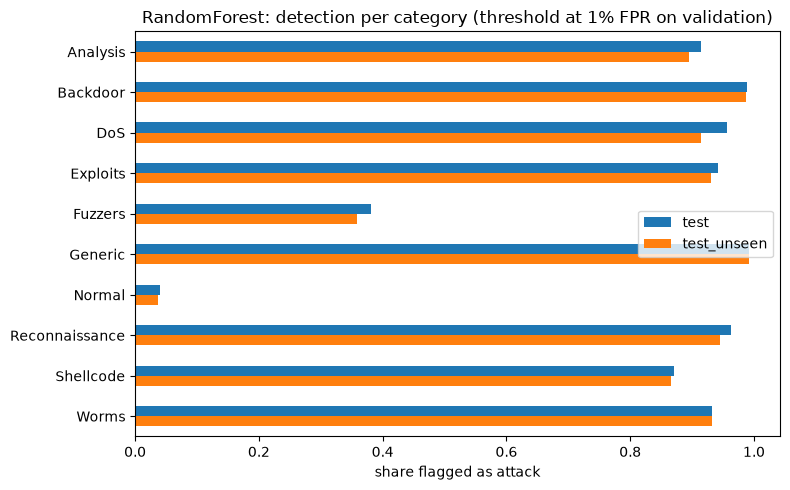

In [19]:
b = binary[best_binary]
fig = plot_roc_pr(y_test, b["scores_test"], f"{best_binary}, test", path=FIGURES_DIR / "binary_roc_pr.png")
plt.show()

ax = by_category[best_binary].plot.barh(figsize=(8, 5))
ax.invert_yaxis()
ax.set_xlabel("share flagged as attack")
ax.set_title(f"{best_binary}: detection per category (threshold at 1% FPR on validation)")
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "binary_detection_by_category.png", dpi=120)
plt.show()

### Why FPR is higher on test

Scores the best binary model gives to normal flows, on validation and on test. The dashed line is the threshold picked on validation.

In [20]:
import numpy as np

b = binary[best_binary]
normal_val = b["model"].predict_proba(X_val[y_val == 0])[:, 1]
normal_test = b["scores_test"][(y_test == 0).to_numpy()]

pd.DataFrame({
    "validation": pd.Series(normal_val).quantile([0.5, 0.9, 0.95, 0.99]),
    "test": pd.Series(normal_test).quantile([0.5, 0.9, 0.95, 0.99]),
}).rename_axis("quantile").round(3)

,validation,test
quantile,,
0.50,0.000,0.002
0.90,0.476,0.762
0.95,0.630,0.847
0.99,0.865,0.936


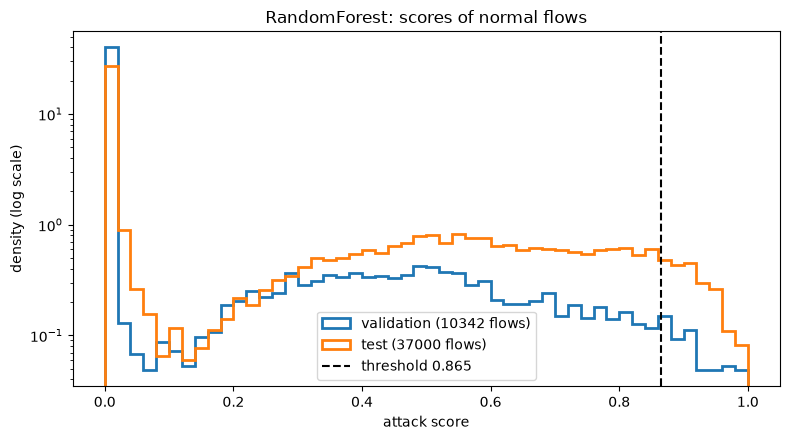

In [21]:
bins = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(normal_val, bins=bins, density=True, histtype="step", linewidth=2, label=f"validation ({len(normal_val)} flows)")
ax.hist(normal_test, bins=bins, density=True, histtype="step", linewidth=2, label=f"test ({len(normal_test)} flows)")
ax.axvline(b["threshold"], color="black", linestyle="--", label=f"threshold {b['threshold']:.3f}")
ax.set_yscale("log")
ax.set_xlabel("attack score")
ax.set_ylabel("density (log scale)")
ax.set_title(f"{best_binary}: scores of normal flows")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "binary_normal_scores.png", dpi=120)
plt.show()

Same FPR with each distinct normal flow counted once, to rule out a few normal flows repeated many times inflating it:

In [22]:
normal_rows = test_df[y_test == 0]
first = ~normal_rows.duplicated(FEATURES).to_numpy()

pd.Series({
    "normal flows": len(normal_rows),
    "distinct normal flows": int(first.sum()),
    "FPR, all rows": (normal_test >= b["threshold"]).mean(),
    "FPR, distinct rows": (normal_test[first] >= b["threshold"]).mean(),
}).round(4)

normal flows             37000.0000
distinct normal flows    34206.0000
FPR, all rows                0.0397
FPR, distinct rows           0.0395
dtype: float64

In [23]:
for name, m in multi.items():
    m.update(evaluate_test(evaluate_multiclass, y_test_multi, m["model"].predict(X_test), unseen, labels=labels))
    save_result(name, "multiclass", {"cv_score": m["cv"], "val": m["val"], "test": m["test"], "test_unseen": m["test_unseen"]}, m["params"])

pd.DataFrame({
    (name, subset): {k: m[subset][k] for k in ["accuracy", "macro_f1", "weighted_f1"]}
    for name, m in multi.items()
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

accuracy  macro_f1  weighted_f1
LogisticRegression   val            0.8093    0.5185       0.8014
                     test           0.7288    0.3994       0.7332
                     test_unseen    0.7418    0.3978       0.7545
RandomForest         val            0.8584    0.7417       0.8652
                     test           0.7028    0.5040       0.7374
                     test_unseen    0.7229    0.5286       0.7550
HistGradientBoosting val            0.8549    0.7379       0.8617
                     test           0.7123    0.5093       0.7452
                     test_unseen    0.7333    0.5299       0.7631

In [24]:
pd.DataFrame({
    name: {cls: v["f1"] for cls, v in m["test"]["per_class"].items()}
    for name, m in multi.items()
}).round(3)

,LogisticRegression,RandomForest,HistGradientBoosting
Analysis,0.000,0.000,0.000
Backdoor,0.088,0.039,0.039
DoS,0.020,0.300,0.294
Exploits,0.664,0.695,0.679
Fuzzers,0.373,0.354,0.369
Generic,0.979,0.985,0.984
Normal,0.804,0.752,0.772
Reconnaissance,0.638,0.859,0.858
Shellcode,0.287,0.396,0.409
Worms,0.140,0.660,0.688


Ceiling: on test, a predictor that knows the test labels and answers with the most frequent class of each feature vector (ties broken arbitrarily).
No model can do better on these rows, see 01_eda.

In [25]:
counts = test_df.groupby(FEATURES + ["attack_cat"]).size().rename("n").reset_index()
majority = counts.sort_values("n", ascending=False).drop_duplicates(FEATURES)[FEATURES + ["attack_cat"]]
oracle = test_df[FEATURES].merge(majority, on=FEATURES, how="left")["attack_cat"]
ceiling = evaluate_multiclass(y_test_multi, oracle, labels)

pd.DataFrame({
    "ceiling": {"accuracy": ceiling["accuracy"], "macro_f1": ceiling["macro_f1"]},
    best_multi: {"accuracy": multi[best_multi]["test"]["accuracy"], "macro_f1": multi[best_multi]["test"]["macro_f1"]},
}).round(4)

,ceiling,RandomForest
accuracy,0.9360,0.7028
macro_f1,0.7634,0.5040


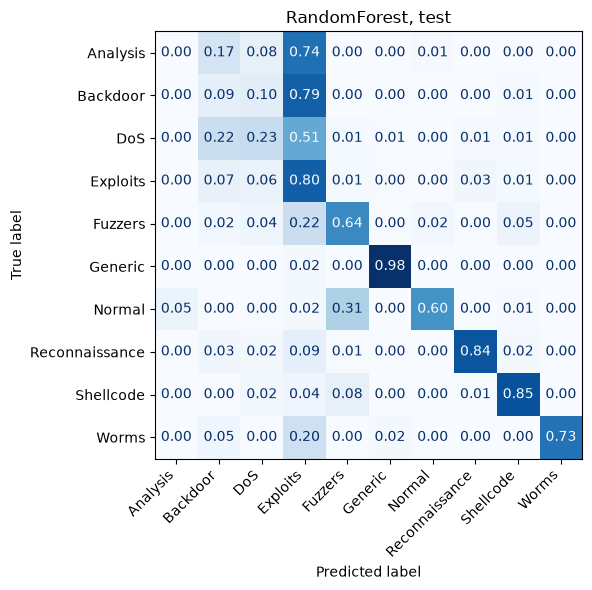

In [26]:
fig = plot_confusion(multi[best_multi]["test"]["confusion_matrix"], labels, f"{best_multi}, test",
                     path=FIGURES_DIR / "multiclass_confusion.png")
plt.show()

## TTL ablation

Best model of each task retrained with the same hyperparameters, without `sttl`, `dttl`, `ct_state_ttl`.
If performance drops a lot, the model leans on how the testbed was wired rather than on how the attacks behave.

In [27]:
def without_ttl(model, X, y):
    return make_pipeline(build_preprocessor(exclude=TTL_COLUMNS), clone(model[-1])).fit(X, y)


b = binary[best_binary]
no_ttl = without_ttl(b["model"], X_tr, y_tr)
s_val = no_ttl.predict_proba(X_val)[:, 1]
threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)
ablation_binary = {
    "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    **evaluate_test(evaluate_binary, y_test, no_ttl.predict_proba(X_test)[:, 1], unseen,
                    categories=y_test_multi, threshold=threshold),
}
save_result(f"{best_binary} (no TTL)", "binary", ablation_binary,
            {"threshold_mode": "fpr", "max_fpr": MAX_FPR, "excluded": TTL_COLUMNS, **b["params"]})

pd.DataFrame({
    (version, subset): {m: res[subset][m] for m in ["recall", "fpr", "precision", "roc_auc"]}
    for version, res in [("with TTL", b), ("no TTL", ablation_binary)]
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

recall     fpr  precision  roc_auc
with TTL val          0.7453  0.0100     0.9862   0.9853
         test         0.8905  0.0397     0.9649   0.9816
         test_unseen  0.8710  0.0374     0.9616   0.9791
no TTL   val          0.7431  0.0100     0.9861   0.9852
         test         0.8856  0.0425     0.9623   0.9801
         test_unseen  0.8651  0.0400     0.9589   0.9774

In [28]:
pd.DataFrame({
    ("with TTL", "test_unseen"): {c: v["flagged"] for c, v in b["test_unseen"]["by_category"].items()},
    ("no TTL", "test_unseen"): {c: v["flagged"] for c, v in ablation_binary["test_unseen"]["by_category"].items()},
}).round(3)

,with TTL,no TTL
,test_unseen,test_unseen
Analysis,0.895,0.893
Backdoor,0.988,0.983
DoS,0.915,0.899
Exploits,0.931,0.921
Fuzzers,0.358,0.351
Generic,0.992,0.989
Normal,0.037,0.040
Reconnaissance,0.944,0.942
Shellcode,0.866,0.868


In [29]:
m = multi[best_multi]
no_ttl_multi = without_ttl(m["model"], Xm_tr, ym_tr)
ablation_multi = {
    "val": evaluate_multiclass(ym_val, no_ttl_multi.predict(Xm_val), labels),
    **evaluate_test(evaluate_multiclass, y_test_multi, no_ttl_multi.predict(X_test), unseen, labels=labels),
}
save_result(f"{best_multi} (no TTL)", "multiclass", ablation_multi, {"excluded": TTL_COLUMNS, **m["params"]})

pd.DataFrame({
    (version, subset): {k: res[subset][k] for k in ["accuracy", "macro_f1"]}
    for version, res in [("with TTL", m), ("no TTL", ablation_multi)]
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

accuracy  macro_f1
with TTL val            0.8584    0.7417
         test           0.7028    0.5040
         test_unseen    0.7229    0.5286
no TTL   val            0.8554    0.7227
         test           0.7000    0.4833
         test_unseen    0.7198    0.5065

## Permutation importance

Best binary model, on validation, with the same partial ROC-AUC score used for tuning. A column's importance is how much the score drops when that column is shuffled.

In [30]:
imp = permutation_importance(binary[best_binary]["model"], X_val, y_val, scoring=pauc,
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({"mean": imp["importances_mean"], "std": imp["importances_std"]},
                          index=X_val.columns).sort_values("mean", ascending=False)
importance.head(15).round(4)

,mean,std
dttl,0.1194,0.0038
sttl,0.1167,0.0035
ct_state_ttl,0.0894,0.0049
ackdat,0.0444,0.0036
sbytes,0.0438,0.0043
service,0.0394,0.0019
dbytes,0.0337,0.0027
ct_srv_src,0.0316,0.0028
ct_srv_dst,0.0299,0.0038
smean,0.0283,0.0026


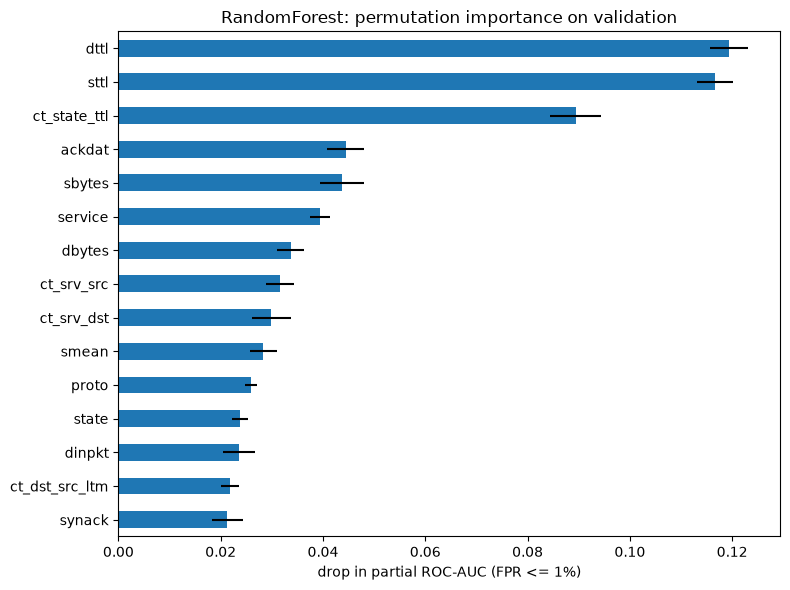

In [31]:
top = importance.head(15)[::-1]
ax = top["mean"].plot.barh(xerr=top["std"], figsize=(8, 6))
ax.set_xlabel("drop in partial ROC-AUC (FPR <= 1%)")
ax.set_title(f"{best_binary}: permutation importance on validation")
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "binary_permutation_importance.png", dpi=120)
plt.show()

## Conclusions

1. **Binary detection works, but the threshold does not transfer.** The threshold was set for 1% FPR on validation. On test the random forest flags 89% of attacks (87% on unseen rows) at 4.0% FPR, gradient boosting 92% at 4.8%. The score distribution shows why: normal flows in the test file get higher scores overall (90th percentile of the random forest score on normal traffic: 0.48 on validation, 0.76 on test), so more of them end up above the threshold. Repeated flows are not the cause: counting each distinct normal flow once gives the same FPR (3.95% vs 3.97%). At 1M normal flows a day that is ~40,000 false alerts instead of the planned 10,000, so in a real deployment the threshold has to be recalibrated on traffic from that network.
2. **Random forest and gradient boosting are tied.** Partial ROC-AUC on validation is 0.825 vs 0.821 (0.820 vs 0.823 in CV). The random forest is kept because the selection rule is the validation score, but gradient boosting is a different trade-off on test: more attacks caught (92% vs 89%) for more false alerts (4.8% vs 4.0%).
3. **Fuzzers is the blind spot.** The random forest flags every other attack category at 87% or more (all above 90% except Shellcode). Fuzzers is caught only 36-52% of the time across the two models, and in multi-class 31% of Normal test flows are predicted as Fuzzers: the two overlap at flow level.
4. **Multi-class hits the limits found in the EDA.** Best model: random forest with `class_weight="balanced"` (balanced weights also won for gradient boosting, not for logistic regression). Macro-F1 is 0.74 on validation but 0.50 on test (0.53 unseen), against a ceiling of 0.76; gradient boosting is level (0.51). Analysis, Backdoor and DoS are mostly predicted as Exploits (F1 0.00, 0.04, 0.30). The binary model still flags 91-99% of them as attacks, so they are detected, just not named correctly.
5. **The models do not depend on TTL, which is not the same as being free of testbed artefacts.** The three TTL columns are the top 3 in permutation importance, yet retraining without them costs little: test recall 89.1% -> 88.6% with FPR 4.0% -> 4.3% (binary), macro-F1 0.50 -> 0.48 (multi-class). High importance with a small ablation cost is the usual sign of redundant features: the same information is available in other columns. Those columns (`state`, `service`, the connection counters) can carry traces of the testbed topology as well, so this experiment cannot show that the models learned attack behaviour rather than the lab setup. Only a test on traffic from a different network would.
6. **Tuning is not the bottleneck.** A wider search with 30 candidates per model moved validation scores by about 0.01 (multi-class macro-F1 even went from 0.754 to 0.742, within the noise of a random search). `min_samples_leaf=1` is the smallest value there is, not a limit of the grid, and 800 trees for the binary forest only lowers variance, more trees would not change the model. The one real edge is `max_features=0.7` for the multi-class forest; given how little the wider search changed, extending it is unlikely to matter.